# 4-loyiha
Tibbiy ma’lumotlarni tozalash va vizuallashtirish

clinical_measurements.csv: sun’iy o‘lchovlar. Review flag diagnostik chegara emas; g‘ayrioddiy qiymatlar yashirilmaydi.


In [1]:
# Tibbiy ma’lumotlarni tozalash va vizuallashtirish
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

ROOT = (Path(__file__).resolve().parent
        if "__file__" in globals() else Path.cwd())
DATA, OUT = ROOT / "data", ROOT / "outputs"
DATA.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)
SEED = 42

def save_json(name, value):
    text = json.dumps(value, indent=2, ensure_ascii=False,
                      allow_nan=False, default=str)
    (OUT / name).write_text(text, encoding="utf-8")

def save_plot(name):
    plt.tight_layout()
    plt.savefig(OUT / name, dpi=140)
    plt.close()

def main():
    path = DATA / "clinical_measurements.csv"
    if not path.exists():
        rng = np.random.default_rng(SEED)
        n = 350
        df = pd.DataFrame({"visit_id": np.arange(n),
            "age": rng.integers(18, 90, n),
            "bmi": rng.normal(26, 5, n),
            "systolic_bp": rng.normal(125, 20, n),
            "glucose": rng.uniform(3, 14, n),
            "glucose_unit": ["mmol/L"] * n})
        df.loc[:15, "glucose"] *= 18
        df.loc[:15, "glucose_unit"] = "mg/dL"
        df.loc[16:23, "bmi"] = np.nan
        df.loc[24, "age"] = -10
        df.loc[25, "glucose"] = 900
        pd.concat([df, df.iloc[:4]], ignore_index=True).to_csv(
            path, index=False)
    raw = pd.read_csv(path)
    exact_duplicate = raw.duplicated()
    raw.loc[exact_duplicate].to_csv(
        OUT / "exact_duplicates.csv", index=False)
    df = raw.loc[~exact_duplicate].copy()
    conflicts = df.visit_id.duplicated(keep=False)
    df["duplicate_id_review"] = conflicts
    for col in ["age", "bmi", "systolic_bp", "glucose"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
        df[col] = df[col].replace([np.inf, -np.inf], np.nan)
    unit = df.glucose_unit.map({"mmol/L": 1, "mg/dL": 1 / 18})
    df["glucose_mmol_l"] = df.glucose * unit
    df["age_review"] = ~df.age.between(0, 120)
    df["glucose_review"] = ~df.glucose_mmol_l.between(1, 40)
    # Xom ustunlar saqlanadi; review qiymatlar o‘chirilmaydi.
    df.to_csv(OUT / "clean_with_flags.csv", index=False)
    numeric = df[["age", "bmi", "systolic_bp", "glucose_mmol_l"]]
    numeric.describe().to_csv(OUT / "descriptive_statistics.csv")
    numeric.isna().mean().to_csv(OUT / "missing_fraction.csv")
    numeric.hist(figsize=(9, 6), bins=20)
    save_plot("histograms.png")
    corr = numeric.corr()
    plt.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
    plt.xticks(range(4), corr.columns, rotation=35, ha="right")
    plt.yticks(range(4), corr.columns)
    plt.colorbar(label="Pearson korrelyatsiyasi")
    save_plot("correlation.png")
    save_json("summary.json", {"raw_rows": len(raw),
        "retained_rows": len(df),
        "exact_duplicates": int(exact_duplicate.sum()),
        "age_review": int(df.age_review.sum()),
        "glucose_review": int(df.glucose_review.sum()),
        "source": "synthetic", "imputation_applied": False})
    print(numeric.describe().round(2).to_string())

if __name__ == "__main__":
    main()


          age     bmi  systolic_bp  glucose_mmol_l
count  350.00  342.00       350.00          350.00
mean    53.27   26.02       123.87           11.04
std     20.14    5.06        20.22           47.76
min    -10.00   11.18        71.54            3.01
25%     37.00   22.62       109.44            5.69
50%     53.00   26.26       124.36            8.33
75%     70.00   29.16       136.71           11.38
max     89.00   40.53       188.58          900.00


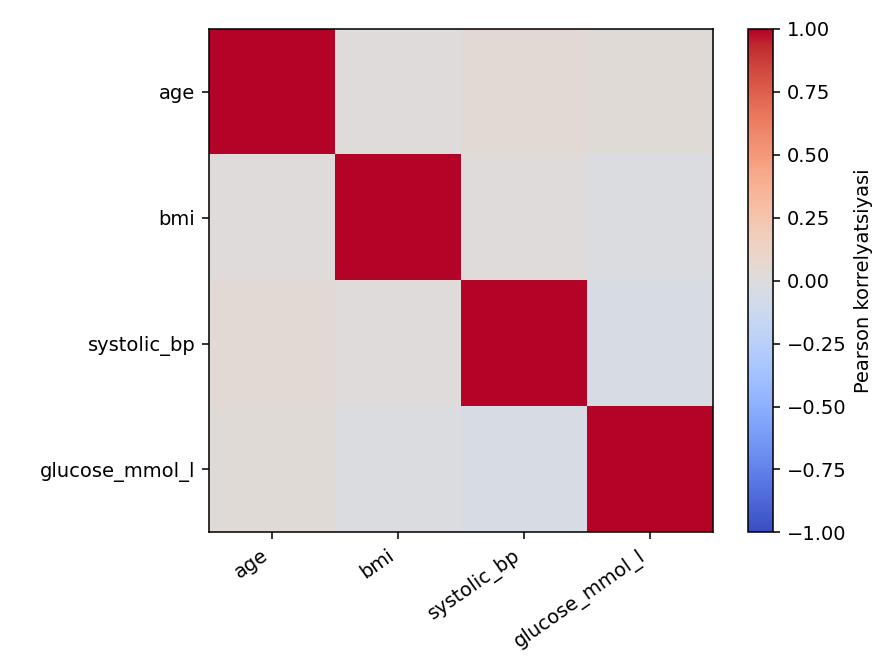

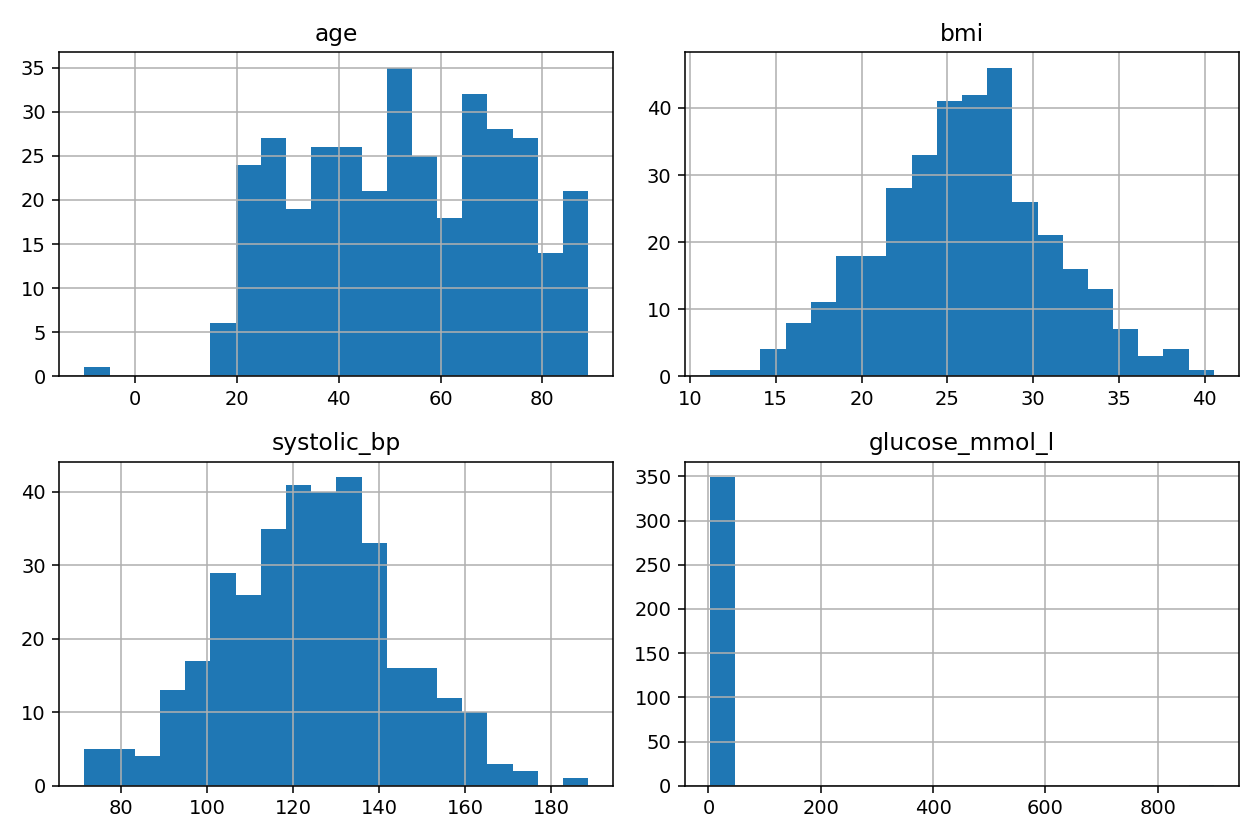

In [2]:
from IPython.display import display, Image
for path in sorted(OUT.glob("*.png")):
    display(Image(filename=str(path)))
